## 라이브러리 설치 & Import

In [1]:
#!pip install matplotlib

In [2]:
# 데이터 처리 및 분석
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import warnings

# 시각화
import matplotlib.pyplot as plt
import seaborn as sns

# 통계 분석
from scipy import stats
from scipy.stats import shapiro, levene, ttest_ind, chi2_contingency, f_oneway
from scipy.stats import mannwhitneyu, fisher_exact, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd, MultiComparison
import pingouin as pg

# 출력 설정
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# 한글 폰트 설정
import platform
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':  # maxOS
    plt.rcParams['font.family'] = 'AppleGothic'
else:  # Linux
    plt.rcParams['font.family'] = 'NanumGothic'
    
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 6)

# 시드 설정
np.random.seed(42)

print("="*60)
print("라이브러리 로드 완료!")
print("한글 폰트 설정 완료!")
print("="*60)

라이브러리 로드 완료!
한글 폰트 설정 완료!


## 데이터 로드

In [3]:
# 데이터 로드
df_articles = pd.read_csv('./datasets/articles_hm.csv')
df_customer = pd.read_csv('./datasets/customer_hm.csv')
df_transaction = pd.read_csv('./datasets/transactions_hm.csv')

## 데이터 조회

In [4]:
df_articles

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105537,953450001,953450,5pk regular Placement1,302,Socks,Socks & Tights,1010014,Placement print,9,Black,4,Dark,5,Black,7188,Socks Bin,F,Menswear,3,Menswear,26,Men Underwear,1021,Socks and Tights,Socks in a fine-knit cotton blend with a small...
105538,953763001,953763,SPORT Malaga tank,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1919,Jersey,A,Ladieswear,1,Ladieswear,2,H&M+,1005,Jersey Fancy,Loose-fitting sports vest top in ribbed fast-d...
105539,956217002,956217,Cartwheel dress,265,Dress,Garment Full body,1010016,Solid,9,Black,4,Dark,5,Black,1641,Jersey,A,Ladieswear,1,Ladieswear,18,Womens Trend,1005,Jersey Fancy,"Short, A-line dress in jersey with a round nec..."
105540,957375001,957375,CLAIRE HAIR CLAW,72,Hair clip,Accessories,1010016,Solid,9,Black,4,Dark,5,Black,3946,Small Accessories,D,Divided,2,Divided,52,Divided Accessories,1019,Accessories,Large plastic hair claw.


#### 행, 열 개수 조회

In [5]:
print("데이터 모양(행, 열):", df_articles.shape)

데이터 모양(행, 열): (105542, 25)


#### 상위 5개, 하위 5개 데이터 조회

In [6]:
display(df_articles.head())
display(df_articles.tail())

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
105537,953450001,953450,5pk regular Placement1,302,Socks,Socks & Tights,1010014,Placement print,9,Black,4,Dark,5,Black,7188,Socks Bin,F,Menswear,3,Menswear,26,Men Underwear,1021,Socks and Tights,Socks in a fine-knit cotton blend with a small...
105538,953763001,953763,SPORT Malaga tank,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1919,Jersey,A,Ladieswear,1,Ladieswear,2,H&M+,1005,Jersey Fancy,Loose-fitting sports vest top in ribbed fast-d...
105539,956217002,956217,Cartwheel dress,265,Dress,Garment Full body,1010016,Solid,9,Black,4,Dark,5,Black,1641,Jersey,A,Ladieswear,1,Ladieswear,18,Womens Trend,1005,Jersey Fancy,"Short, A-line dress in jersey with a round nec..."
105540,957375001,957375,CLAIRE HAIR CLAW,72,Hair clip,Accessories,1010016,Solid,9,Black,4,Dark,5,Black,3946,Small Accessories,D,Divided,2,Divided,52,Divided Accessories,1019,Accessories,Large plastic hair claw.
105541,959461001,959461,Lounge dress,265,Dress,Garment Full body,1010016,Solid,11,Off White,1,Dusty Light,9,White,1641,Jersey,A,Ladieswear,1,Ladieswear,18,Womens Trend,1005,Jersey Fancy,Calf-length dress in ribbed jersey made from a...


#### 컬럼명 조회

In [7]:
df_articles.columns

Index(['article_id', 'product_code', 'prod_name', 'product_type_no',
       'product_type_name', 'product_group_name', 'graphical_appearance_no',
       'graphical_appearance_name', 'colour_group_code', 'colour_group_name',
       'perceived_colour_value_id', 'perceived_colour_value_name',
       'perceived_colour_master_id', 'perceived_colour_master_name',
       'department_no', 'department_name', 'index_code', 'index_name',
       'index_group_no', 'index_group_name', 'section_no', 'section_name',
       'garment_group_no', 'garment_group_name', 'detail_desc'],
      dtype='str')

#### 전체구조 파악
- (행/열 개수, 컬럼별 데이터 타입, non-null 개수 조회)

In [8]:
df_articles.info()

<class 'pandas.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   article_id                    105542 non-null  int64
 1   product_code                  105542 non-null  int64
 2   prod_name                     105542 non-null  str  
 3   product_type_no               105542 non-null  int64
 4   product_type_name             105542 non-null  str  
 5   product_group_name            105542 non-null  str  
 6   graphical_appearance_no       105542 non-null  int64
 7   graphical_appearance_name     105542 non-null  str  
 8   colour_group_code             105542 non-null  int64
 9   colour_group_name             105542 non-null  str  
 10  perceived_colour_value_id     105542 non-null  int64
 11  perceived_colour_value_name   105542 non-null  str  
 12  perceived_colour_master_id    105542 non-null  int64
 13  perceived_colour_master_n

#### 각 컬럼별 결측치 개수 확인

In [9]:
df_articles.isna().sum()

article_id                        0
product_code                      0
prod_name                         0
product_type_no                   0
product_type_name                 0
product_group_name                0
graphical_appearance_no           0
graphical_appearance_name         0
colour_group_code                 0
colour_group_name                 0
perceived_colour_value_id         0
perceived_colour_value_name       0
perceived_colour_master_id        0
perceived_colour_master_name      0
department_no                     0
department_name                   0
index_code                        0
index_name                        0
index_group_no                    0
index_group_name                  0
section_no                        0
section_name                      0
garment_group_no                  0
garment_group_name                0
detail_desc                     416
dtype: int64

#### 값의 분포, 통계치 확인
- (count, mean, std, min, 25%, 50%, 75%, max)

In [10]:
df_articles.describe()

,article_id,product_code,product_type_no,graphical_appearance_no,colour_group_code,perceived_colour_value_id,perceived_colour_master_id,department_no,index_group_no,section_no,garment_group_no
count,1.055420e+05,105542.000000,105542.000000,1.055420e+05,105542.000000,105542.000000,105542.000000,105542.000000,105542.000000,105542.000000,105542.000000
mean,6.984246e+08,698424.563378,234.861875,1.009515e+06,32.233822,3.206183,7.807972,4532.777833,3.171534,42.664219,1010.438290
std,1.284624e+08,128462.384432,75.049308,2.241359e+04,28.086154,1.563839,5.376727,2712.692011,4.353234,23.260105,6.731023
min,1.087750e+08,108775.000000,-1.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,1201.000000,1.000000,2.000000,1001.000000
25%,6.169925e+08,616992.500000,252.000000,1.010008e+06,9.000000,2.000000,4.000000,1676.000000,1.000000,20.000000,1005.000000
50%,7.022130e+08,702213.000000,259.000000,1.010016e+06,14.000000,4.000000,5.000000,4222.000000,2.000000,46.000000,1009.000000
75%,7.967030e+08,796703.000000,272.000000,1.010016e+06,52.000000,4.000000,11.000000,7389.000000,4.000000,61.000000,1017.000000
max,9.594610e+08,959461.000000,762.000000,1.010029e+06,93.000000,7.000000,20.000000,9989.000000,26.000000,97.000000,1025.000000


#### Grain(식별 기준) 파악하기
- 식별자(Primary Key) 찾기
    - `id`, `code`, `no`

In [11]:
# 전체 행 개수
total_rows = len(df_articles)
print(f"전체 행 개수: {total_rows}\n")

# 각 컬럼별 고유값 개수
for col in df_articles.columns:
    if 'id' in col.lower() or 'code' in col.lower() or 'no' in col.lower():
        unique_cnt = df_articles[col].nunique()
        print(f"컬럼 [{col}]의 유일값 개수: {unique_cnt} (전체 행 대비 비중: {unique_cnt/total_rows*100:.1f}%)")

전체 행 개수: 105542

컬럼 [article_id]의 유일값 개수: 105542 (전체 행 대비 비중: 100.0%)
컬럼 [product_code]의 유일값 개수: 47224 (전체 행 대비 비중: 44.7%)
컬럼 [product_type_no]의 유일값 개수: 132 (전체 행 대비 비중: 0.1%)
컬럼 [graphical_appearance_no]의 유일값 개수: 30 (전체 행 대비 비중: 0.0%)
컬럼 [colour_group_code]의 유일값 개수: 50 (전체 행 대비 비중: 0.0%)
컬럼 [perceived_colour_value_id]의 유일값 개수: 8 (전체 행 대비 비중: 0.0%)
컬럼 [perceived_colour_master_id]의 유일값 개수: 20 (전체 행 대비 비중: 0.0%)
컬럼 [department_no]의 유일값 개수: 299 (전체 행 대비 비중: 0.3%)
컬럼 [index_code]의 유일값 개수: 10 (전체 행 대비 비중: 0.0%)
컬럼 [index_group_no]의 유일값 개수: 5 (전체 행 대비 비중: 0.0%)
컬럼 [section_no]의 유일값 개수: 57 (전체 행 대비 비중: 0.1%)
컬럼 [garment_group_no]의 유일값 개수: 21 (전체 행 대비 비중: 0.0%)


#### 결측치 비율 파악

In [12]:
# 컬럼별 결측치 개수 및 비율 확인
null_PCT = pd.DataFrame({
    '결측치_개수': df_articles.isnull().sum(),
    '결측치_비율(%)': (df_articles.isnull().sum() / len(df_articles) * 100).round(2)
})

# 결측치가 1개 이상 있는 컬럼만 출력
null_PCT[null_PCT['결측치_개수'] > 0]

,결측치_개수,결측치_비율(%)
detail_desc,416,0.39


#### 수치 기반 이상치 및 분포 확인

In [13]:
# 1. 수치형 컬럼 전체의 요약 통계량 확인
display(df_articles.describe().T)

# 2. 수치형 컬럼만 자동 추출한 뒤, 전체 분위수(Quantile) 확인
numeric_df = df_articles.select_dtypes(include=['number'])

# 수치형 컬럼이 1개라도 존재하는지 체크
if not numeric_df.empty:
    print("--- 모든 수치형 컬럼의 상세 분위수 확인 ---")
    # numeric_df 자체에 .quantile()을 적용하면 모든 수치형 컬럼이 한눈에 조회 가능
    display(numeric_df.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]))
else:
    print("이 데이터에는 수치형 컬럼이 없습니다.")

,count,mean,std,min,25%,50%,75%,max
article_id,105542.0,6.984246e+08,1.284624e+08,108775015.0,616992501.0,702213001.5,7.967030e+08,959461001.0
product_code,105542.0,6.984246e+05,1.284624e+05,108775.0,616992.5,702213.0,7.967030e+05,959461.0
product_type_no,105542.0,2.348619e+02,7.504931e+01,-1.0,252.0,259.0,2.720000e+02,762.0
graphical_appearance_no,105542.0,1.009515e+06,2.241359e+04,-1.0,1010008.0,1010016.0,1.010016e+06,1010029.0
colour_group_code,105542.0,3.223382e+01,2.808615e+01,-1.0,9.0,14.0,5.200000e+01,93.0
perceived_colour_value_id,105542.0,3.206183e+00,1.563839e+00,-1.0,2.0,4.0,4.000000e+00,7.0
perceived_colour_master_id,105542.0,7.807972e+00,5.376727e+00,-1.0,4.0,5.0,1.100000e+01,20.0
department_no,105542.0,4.532778e+03,2.712692e+03,1201.0,1676.0,4222.0,7.389000e+03,9989.0
index_group_no,105542.0,3.171534e+00,4.353234e+00,1.0,1.0,2.0,4.000000e+00,26.0
section_no,105542.0,4.266422e+01,2.326010e+01,2.0,20.0,46.0,6.100000e+01,97.0


--- 모든 수치형 컬럼의 상세 분위수 확인 ---


,article_id,product_code,product_type_no,graphical_appearance_no,colour_group_code,perceived_colour_value_id,perceived_colour_master_id,department_no,index_group_no,section_no,garment_group_no
0.01,3.155090e+08,315509.00,59.0,1010001.0,5.0,1.0,1.0,1212.0,1.0,2.0,1001.0
0.05,4.938100e+08,493810.00,70.0,1010001.0,7.0,1.0,2.0,1338.0,1.0,6.0,1002.0
0.25,6.169925e+08,616992.50,252.0,1010008.0,9.0,2.0,4.0,1676.0,1.0,20.0,1005.0
0.50,7.022130e+08,702213.00,259.0,1010016.0,14.0,4.0,5.0,4222.0,2.0,46.0,1009.0
0.75,7.967030e+08,796703.00,272.0,1010016.0,52.0,4.0,11.0,7389.0,4.0,61.0,1017.0
0.95,8.893790e+08,889379.00,304.0,1010023.0,81.0,7.0,19.0,8748.0,4.0,77.0,1020.0
0.99,9.234635e+08,923463.54,308.0,1010026.0,93.0,7.0,20.0,9985.0,26.0,82.0,1025.0
1.00,9.594610e+08,959461.00,762.0,1010029.0,93.0,7.0,20.0,9989.0,26.0,97.0,1025.0


#### 문자/범주형 데이터 종류 확인

In [14]:
# 1. 범주형 컬럼 목록 자동 추출
cat_cols = df_articles.select_dtypes(include=['object', 'category']).columns

# 2. 범주형 컬럼을 하나씩 순회하며 빈도수 출력
for col in cat_cols:
    print(f"=== 컬럼: [{col}] ===")
    print(f"종류 수(nunique): {df_articles[col].nunique()}")
    print(df_articles[col].value_counts(dropna=False).head(10))
    print("-" * 30)

=== 컬럼: [prod_name] ===
종류 수(nunique): 45875
prod_name
Dragonfly dress          98
Mike tee                 72
Wow printed tee 6.99     70
1pk Fun                  55
TP Paddington Sweater    54
Pria tee                 51
Despacito                48
MY                       44
Robin 3pk Fancy          43
Eivor 7-p shaftless      42
Name: count, dtype: int64
------------------------------
=== 컬럼: [product_type_name] ===
종류 수(nunique): 131
product_type_name
Trousers    11169
Dress       10362
Sweater      9302
T-shirt      7904
Top          4155
Blouse       3979
Jacket       3940
Shorts       3939
Shirt        3405
Vest top     2991
Name: count, dtype: int64
------------------------------
=== 컬럼: [product_group_name] ===
종류 수(nunique): 19
product_group_name
Garment Upper body    42741
Garment Lower body    19812
Garment Full body     13292
Accessories           11158
Underwear              5490
Shoes                  5283
Swimwear               3127
Socks & Tights         2442
Nightwea

#### 숨은 결측치 문자 체크

In [15]:
# 1. 범주형(문자형) 컬럼 목록 자동 추출
cat_cols = df_articles.select_dtypes(include=['object', 'category']).columns

# 2. 체크하고 싶은 '숨은 결측치 문자' 목록
missing_indicators = ['Unknown', 'unknown', 'None', '-', '?']

print("=== 범주형 컬럼 내 텍스트 결측치 점검 결과 ===")

# 모든 범주형 컬럼을 돌면서 확인
for col in cat_cols:
    for indicator in missing_indicators:
        # 해당 문자가 들어있는 개수 세기
        count = (df_articles[col] == indicator).sum()
        
        # 1개라도 발견되면 출력
        if count > 0:
            print(f"[{col}] 컬럼에 '{indicator}' 값이 {count}개 존재합니다.")

=== 범주형 컬럼 내 텍스트 결측치 점검 결과 ===
[product_type_name] 컬럼에 'Unknown' 값이 121개 존재합니다.
[product_group_name] 컬럼에 'Unknown' 값이 121개 존재합니다.
[graphical_appearance_name] 컬럼에 'Unknown' 값이 52개 존재합니다.
[colour_group_name] 컬럼에 'Unknown' 값이 28개 존재합니다.
[perceived_colour_value_name] 컬럼에 'Unknown' 값이 28개 존재합니다.
[perceived_colour_master_name] 컬럼에 'Unknown' 값이 685개 존재합니다.
[garment_group_name] 컬럼에 'Unknown' 값이 3873개 존재합니다.


#### 오탈자 및 띄어쓰기 문제 확인

In [16]:
# 모든 범주형 컬럼에 대해 공백 문제 및 오탈자 가능성 점검
for col in cat_cols:
    original_nunique = df_articles[col].nunique()
    
    # 양쪽 공백을 제거(.str.strip())했을 때의 종류 수 계산
    cleaned_nunique = df_articles[col].astype(str).str.strip().nunique()
    
    if original_nunique != cleaned_nunique:
        print(f" [{col}] 컬럼: 띄어쓰기/공백 문제 존재")
        print(f"  - 원본 종류 수: {original_nunique}개 -> 공백 제거 후: {cleaned_nunique}개")

#### 클래스 불균형 (한 항목 99% 독점) 확인하기
- 분석 가치 없는 컬럼이라 삭제해야 함

In [17]:
print("=== 클래스 불균형 (특정 항목 95% 이상 독점) 점검 ===")

for col in cat_cols:
    # normalize=True를 주면 비율(0~1)로 나옴
    top_ratio = df_articles[col].value_counts(normalize=True, dropna=False).iloc[0]
    top_value = df_articles[col].value_counts(dropna=False).index[0]
    
    # 1등 항목이 전체의 95%(0.95) 이상을 차지하는 경우 경고 출력
    if top_ratio >= 0.95:
        print(f" [{col}] 컬럼: 클래스 불균형 존재")
        print(f"  - 가장 많은 값: '{top_value}' ({top_ratio*100:.1f}%)")

=== 클래스 불균형 (특정 항목 95% 이상 독점) 점검 ===


#### 중복 데이터 조회 및 처리

In [18]:
# 전체 테이블에서 완전히 똑같은 중복 행이 몇 개 있는지 확인
print("완전 중복 행 개수:", df_articles.duplicated().sum())

# 중복 데이터만 뽑아서 article_id 순으로 정렬해서 보기
duplicate_rows = df_articles[df_articles.duplicated(keep=False)]
display(duplicate_rows.sort_values(by=['article_id']).head(10))

# df_articles의 PK인 article_id가 중복된 적이 있는지 확인
print("article_id 중복 개수:", df_articles.duplicated(subset=['article_id']).sum())

완전 중복 행 개수: 0


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc


article_id 중복 개수: 0


#### 코드(_no)와 명칭(_name) 간 1:1 매핑 일치 확인

In [19]:
cols = df_articles.columns
for name_col in cols[cols.str.endswith('_name')]:
    base = name_col[:-len('_name')]
    code_col = next((base + s for s in ('_no', '_code', '_id') if base + s in cols), None)
    if code_col is None:
        continue
    pairs = df_articles[[code_col, name_col]].drop_duplicates()
    if pairs[code_col].is_unique and pairs[name_col].is_unique:
        print(f"-: {code_col} <-> {name_col} : 1:1 매핑")
    else:
        print(f"불일치: {code_col} <-> {name_col} : 불일치 (코드 중복 {pairs[code_col].duplicated().sum()}, 이름 중복 {pairs[name_col].duplicated().sum()})")

불일치: product_type_no <-> product_type_name : 불일치 (코드 중복 0, 이름 중복 1)
-: graphical_appearance_no <-> graphical_appearance_name : 1:1 매핑
-: colour_group_code <-> colour_group_name : 1:1 매핑
-: perceived_colour_value_id <-> perceived_colour_value_name : 1:1 매핑
-: perceived_colour_master_id <-> perceived_colour_master_name : 1:1 매핑
불일치: department_no <-> department_name : 불일치 (코드 중복 0, 이름 중복 49)
-: index_code <-> index_name : 1:1 매핑
-: index_group_no <-> index_group_name : 1:1 매핑
불일치: section_no <-> section_name : 불일치 (코드 중복 0, 이름 중복 1)
-: garment_group_no <-> garment_group_name : 1:1 매핑


#### 수치 간 상관관계 히트맵
- 수치형 데이터 존재X -> 히트맵X

In [27]:
# 수치형 컬럼 추출
numeric_cols = df_articles.select_dtypes(include=["number"]).columns.tolist()

# _id, _code, _no 가 들어간 컬럼을 '대소문자 구분 없이' 제거
clean_numeric_cols = [col for col in numeric_cols
    if not any(k in col.lower() for k in ["id", "code", "no"])]

print("제거 후 남아있는 진짜 수치형 컬럼 목록:", clean_numeric_cols)

# 남아있는 수치형 컬럼이 2개 이상일 때만 히트맵 실행
if len(clean_numeric_cols) >= 2:
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        df_articles[clean_numeric_cols].corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
    )
    plt.title("Correlation Heatmap")
    plt.show()
else:
    print(
        "\n 확인 완료: ID/코드성 번호를 제외하면 진짜 숫자(가격, 수량 등) 변수가 존재하지 않습니다."
    )

제거 후 남아있는 진짜 수치형 컬럼 목록: []

 확인 완료: ID/코드성 번호를 제외하면 진짜 숫자(가격, 수량 등) 변수가 존재하지 않습니다.


#### 범주형 변수 비중 확인

시각화에 적합한 범주형 컬럼 목록: ['product_group_name', 'graphical_appearance_name', 'perceived_colour_value_name', 'perceived_colour_master_name', 'index_name', 'index_group_name', 'garment_group_name']


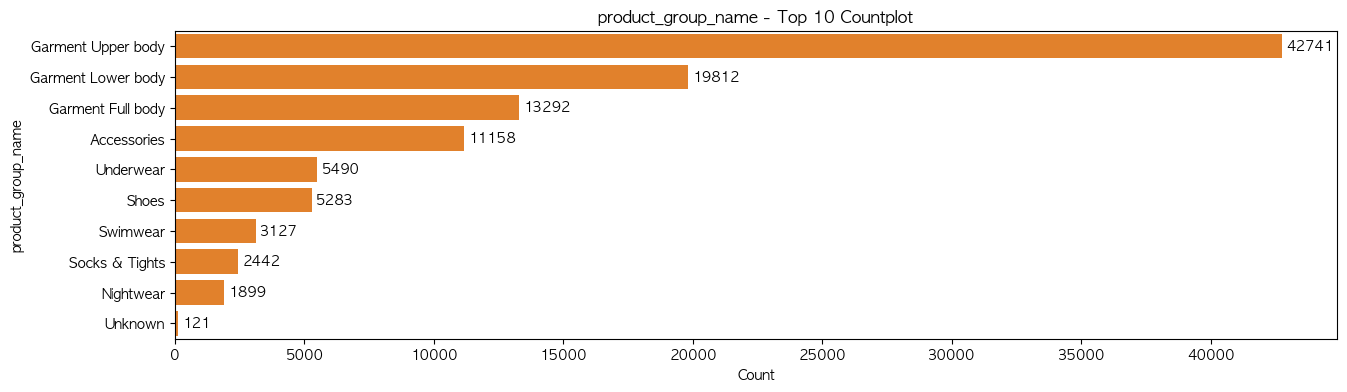

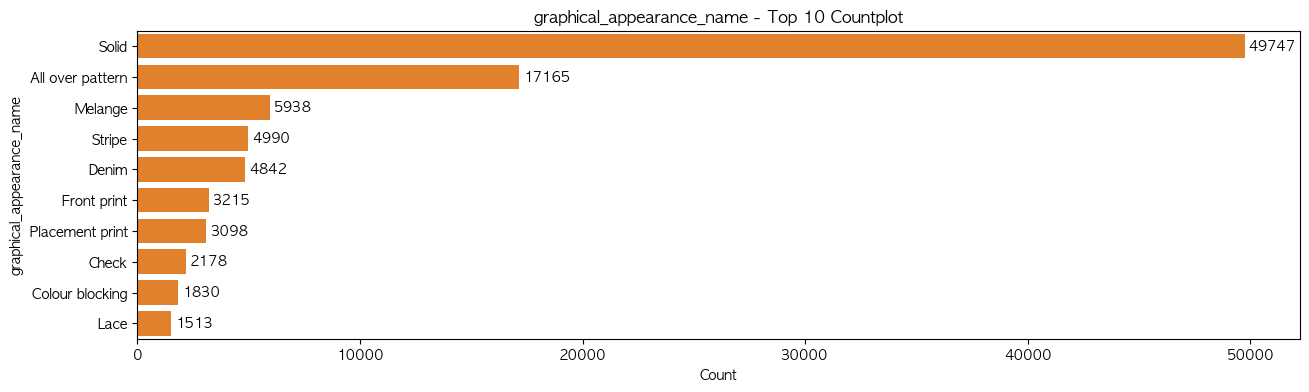

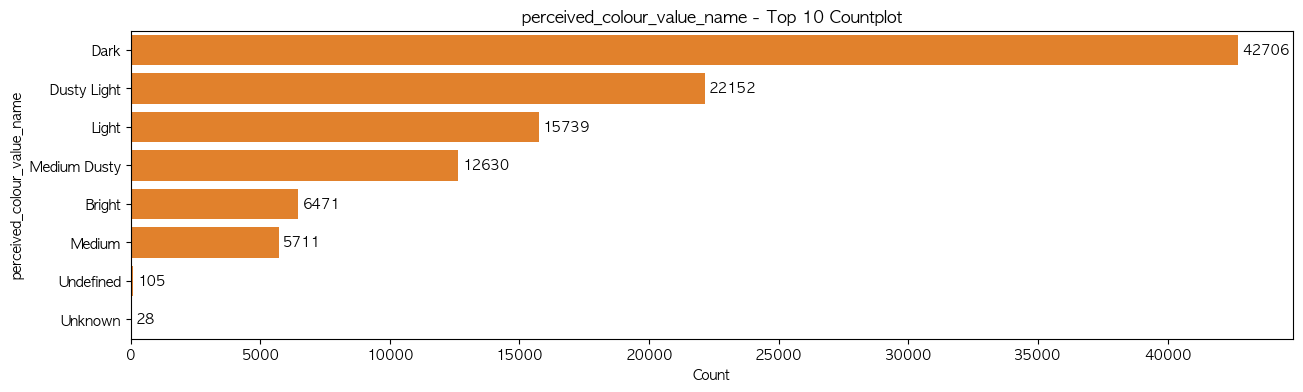

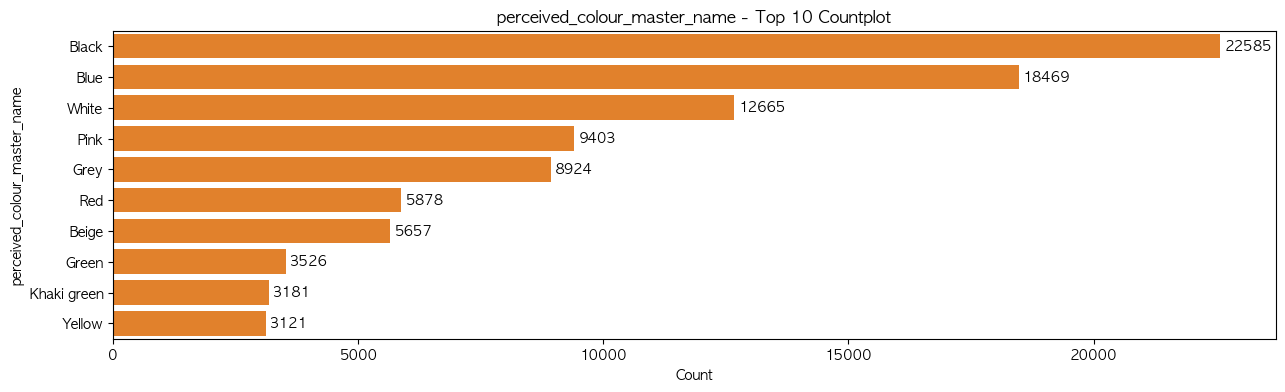

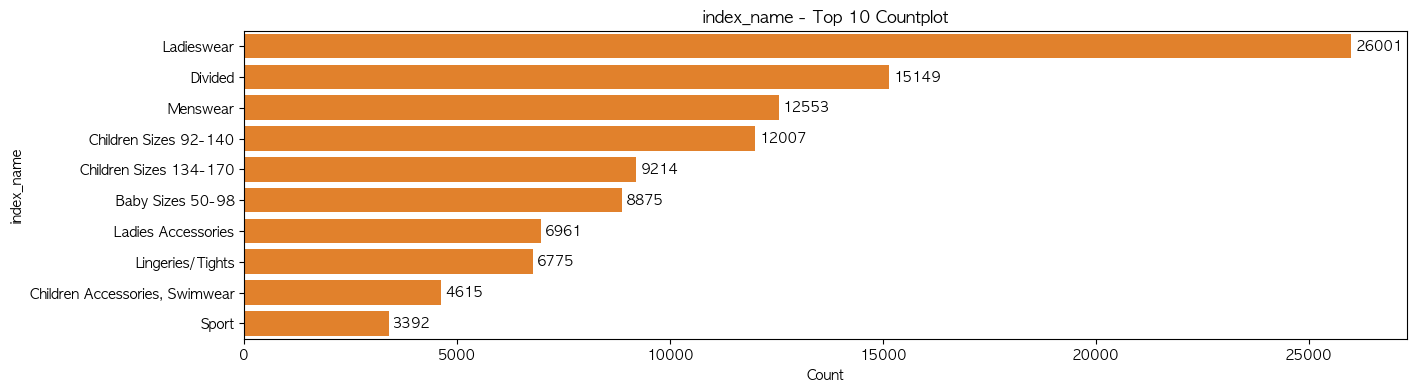

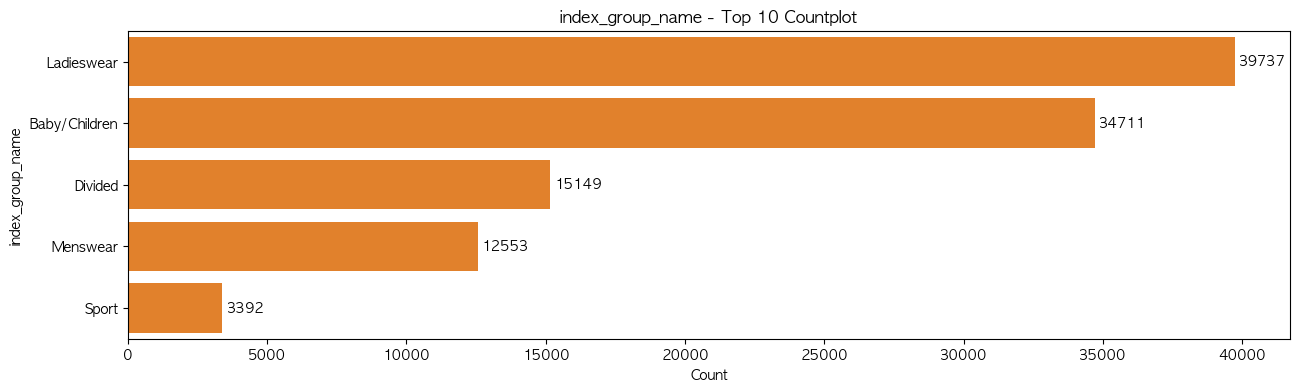

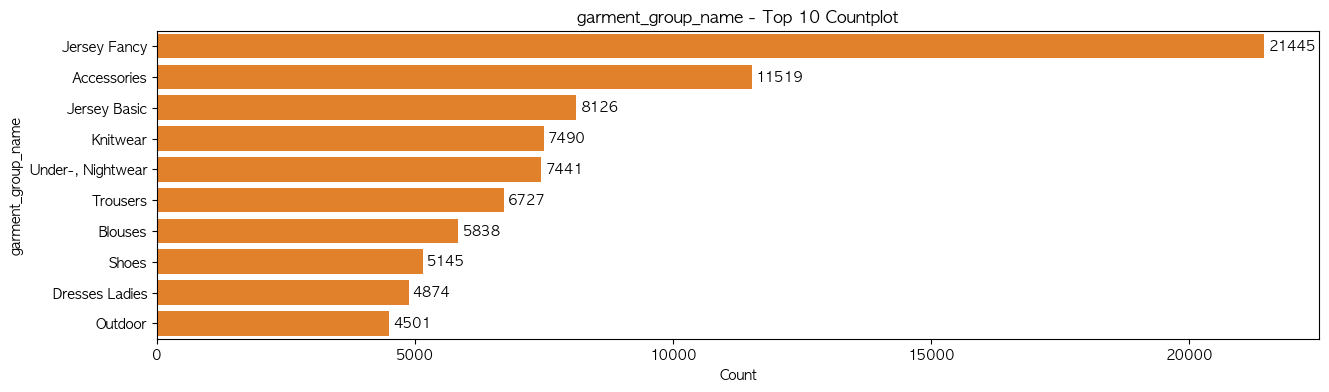

In [35]:
# 글자(범주형) 컬럼만 추출
cat_cols = df_articles.select_dtypes(include=["object", "category"]).columns.tolist()

# 고유값(종류)이 너무 많은 컬럼(예: 30개 초과) 및 ID/설명 컬럼 자동 제외
filtered_cat_cols = [col for col in cat_cols
    if df_articles[col].nunique() <= 30  # 카테고리 종류가 30개 이하인 것만 선별
    and not any(k in col.lower() for k in ["id", "code", "no", "desc", "name_length"])]

print("시각화에 적합한 범주형 컬럼 목록:", filtered_cat_cols)

# 선별된 진짜 범주형 컬럼들만 countplot 그리기
for col in filtered_cat_cols:
    plt.figure(figsize=(15, 4))
    # 데이터 상위 10개만 골라 시각화
    top_10 = df_articles[col].value_counts().head(10).index
    sns.countplot(
        data=df_articles[df_articles[col].isin(top_10)],
        y=col,
        order=top_10,)
    
    ax = sns.countplot(
        data=df_articles[df_articles[col].isin(top_10)],
        y=col,
        order=top_10,)
    
    ax.bar_label(ax.containers[0], fmt="%d", padding=3)

    plt.title(f"{col} - Top 10 Countplot")
    plt.xlabel("Count")
    plt.show()

#### 범주형 데이터 고유값 빈도수(개수) 확인(결측치 제외)

In [46]:
# 제외할 컬럼 목록 직접 지정 (detail_desc, customer_id 등)
exclude_cols = ['detail_desc', 'customer_id']

# 범주형 컬럼 중 제외 목록만 빼고 선택
categorical_cols = [c for c in df_articles.select_dtypes(include=['object', 'category']).columns if c not in exclude_cols]

# 고유값 빈도 및 비율 출력
for col in categorical_cols:
    print(f"=== {col} ===")
    counts = df_articles[col].value_counts()  # dropna=True (기본값)
    probs = df_articles[col].value_counts(normalize=True) * 100
    
    summary = pd.DataFrame({'Count': counts, 'Percentage (%)': probs.round(2)})
    display(summary)
    print("\n")

=== prod_name ===


,Count,Percentage (%)
prod_name,,
Dragonfly dress,98,0.09
Mike tee,72,0.07
Wow printed tee 6.99,70,0.07
1pk Fun,55,0.05
TP Paddington Sweater,54,0.05
...,...,...
5pk regular Placement1,1,0.00
SPORT Malaga tank,1,0.00
Cartwheel dress,1,0.00




=== product_type_name ===


,Count,Percentage (%)
product_type_name,,
Trousers,11169,10.58
Dress,10362,9.82
Sweater,9302,8.81
T-shirt,7904,7.49
Top,4155,3.94
...,...,...
Towel,1,0.00
Wood balls,1,0.00
Pre-walkers,1,0.00




=== product_group_name ===


,Count,Percentage (%)
product_group_name,,
Garment Upper body,42741,40.50
Garment Lower body,19812,18.77
Garment Full body,13292,12.59
Accessories,11158,10.57
Underwear,5490,5.20
Shoes,5283,5.01
Swimwear,3127,2.96
Socks & Tights,2442,2.31
Nightwear,1899,1.80


... (16 outputs left out)



=== section_name ===


,Count,Percentage (%)
section_name,,
Womens Everyday Collection,7295,6.91
Divided Collection,7124,6.75
Baby Essentials & Complements,4932,4.67
Kids Girl,4469,4.23
Young Girl,3899,3.69
Womens Lingerie,3598,3.41
Girls Underwear & Basics,3490,3.31
Womens Tailoring,3376,3.20
Kids Boy,3328,3.15




=== garment_group_name ===


,Count,Percentage (%)
garment_group_name,,
Jersey Fancy,21445,20.32
Accessories,11519,10.91
Jersey Basic,8126,7.70
Knitwear,7490,7.10
"Under-, Nightwear",7441,7.05
Trousers,6727,6.37
Blouses,5838,5.53
Shoes,5145,4.87
Dresses Ladies,4874,4.62
